In [12]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)

# Function to fetch game metrics from SteamSpy API
def fetch_steamspy_data(appid):
    url = f"https://steamspy.com/api.php?request=appdetails&appid={appid}"
    headers = {'User-Agent': 'Mozilla/5.0'}
    response = requests.get(url, headers=headers)
    if response.status_code == 200:
        return response.json()
    return None

# Target game titles and their AppIDs
games_dict = {
    'CS2': 730,
    'Deadlock': 1422450,
    'Dota 2': 570
}

collected_data = []
for label, appid in games_dict.items():
    game_info = fetch_steamspy_data(appid)
    if game_info:
        game_info['custom_label'] = label
        collected_data.append(game_info)

# Constructing DataFrame and selecting key metrics
df_games = pd.DataFrame(collected_data)
core_features = ['custom_label', 'name', 'positive', 'negative', 'ccu', 'average_forever', 'median_forever', 'price']
df_metrics = df_games[core_features].copy()

# Calculate positive review ratio percentage
df_metrics['positive_ratio'] = (
    df_metrics['positive'] / (df_metrics['positive'] + df_metrics['negative'])
) * 100

df_metrics

,custom_label,name,positive,negative,ccu,average_forever,median_forever,price,positive_ratio
0,CS2,Counter-Strike: Global Offensive,7642084,1173003,1013936,0,0,0,86.693234
1,Deadlock,Deadlock,0,0,0,0,0,NaN,NaN
2,Dota 2,Dota 2,2037143,461826,623941,0,0,0,81.519339


C:\Users\alivo\AppData\Local\Temp\ipykernel_17220\314003275.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_metrics, x='custom_label', y='ccu', palette='viridis', ax=axes[0])
C:\Users\alivo\AppData\Local\Temp\ipykernel_17220\314003275.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_metrics, x='custom_label', y='positive_ratio', palette='mako', ax=axes[1])


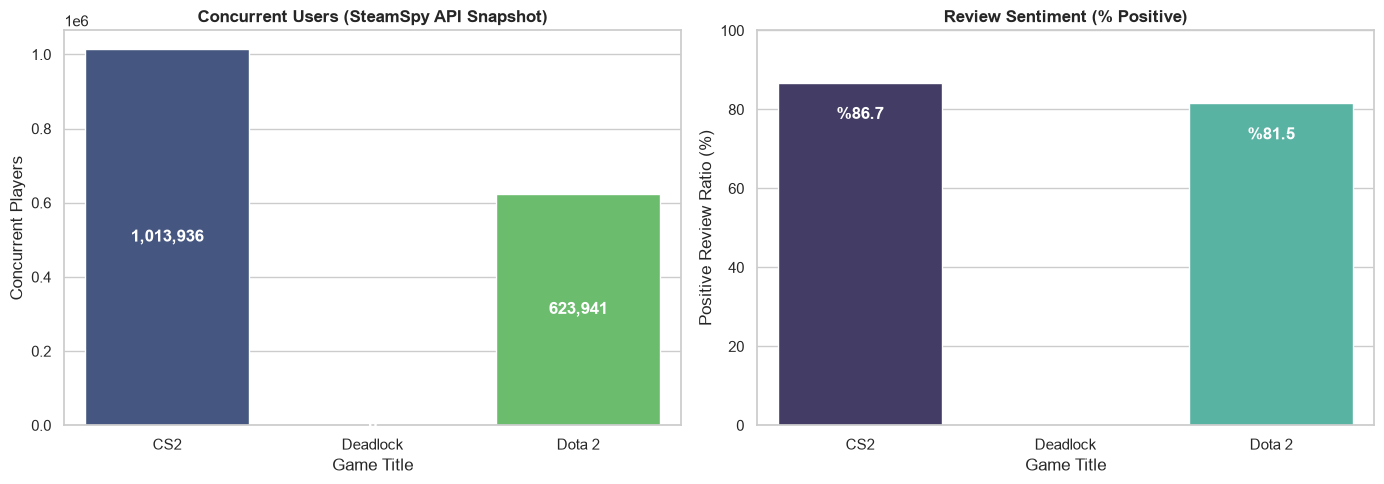

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Peak/Current Concurrent Users (CCU)
sns.barplot(data=df_metrics, x='custom_label', y='ccu', palette='viridis', ax=axes[0])
axes[0].set_title('Concurrent Users (SteamSpy API Snapshot)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Game Title')
axes[0].set_ylabel('Concurrent Players')

for patch in axes[0].patches:
    height_val = int(patch.get_height())
    axes[0].annotate(f'{height_val:,}', 
                     (patch.get_x() + patch.get_width() / 2., patch.get_height() / 2), 
                     ha='center', va='center', color='white', fontweight='bold')

# Plot 2: Community Sentiment (% Positive Reviews)
sns.barplot(data=df_metrics, x='custom_label', y='positive_ratio', palette='mako', ax=axes[1])
axes[1].set_title('Review Sentiment (% Positive)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Game Title')
axes[1].set_ylabel('Positive Review Ratio (%)')
axes[1].set_ylim(0, 100)

for patch in axes[1].patches:
    height_val = patch.get_height()
    if pd.notna(height_val):
        axes[1].annotate(f'%{height_val:.1f}', 
                         (patch.get_x() + patch.get_width() / 2., height_val - 8), 
                         ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
This chart illustrates three distinct game genres with three different player profiles, all originating from Valve.

CS2: A legendary FPS title. Most players return to this game due to its sustainable competitive ecosystem, large community, and accessible mechanics; even if you take a break from CS, you don't fall behind mechanically. Looking at the review summary, the positive reviews outnumber the negative ones by roughly 6 to 1.

Dota 2: Another legendary title, but in the MOBA genre. Dota has a niche and dedicated community that remains remarkably stable over time—neither surging nor declining sharply. Although it is a relatively old game, it consistently receives major updates. Its sentiment ratio is slightly lower than CS2's, with positive reviews sitting at roughly 5 times the negative reviews.

Platform Context: These figures might not capture the entire industry picture because all three titles are exclusive to Steam, and Valve owns the platform. We must factor in this distribution advantage before drawing definitive conclusions.

In [16]:
# 1. Güvenilir iki metrik üzerinden yeniden ağırlıklandırma (CCU %70, Pozitif Oran %30)
cs2_ccu = df_metrics.loc[df_metrics['custom_label'] == 'CS2', 'ccu'].values[0]

df_metrics['sustainability_score'] = (
    (df_metrics['ccu'] / (cs2_ccu if cs2_ccu > 0 else 1)) * 70 +
    (df_metrics['positive_ratio'].fillna(0) / 100) * 30
).round(2)

# 2. Seviye (Tier) ataması
def assign_sustainability_tier(score):
    if score >= 85:
        return 'Tier 1: Industry Giant (CS-Tier)'
    elif score >= 50:
        return 'Tier 2: Resilient Cult Classic (Dota-Tier)'
    elif score >= 25:
        return 'Tier 3: Moderate / Fragile Retention'
    else:
        return 'Tier 4: High Drop-off Risk'

df_metrics['tier_category'] = df_metrics['sustainability_score'].apply(assign_sustainability_tier)

# Temiz çıktı tablosu
display_cols = ['custom_label', 'ccu', 'positive_ratio', 'sustainability_score', 'tier_category']
print(df_metrics[display_cols].to_string(index=False))

custom_label     ccu  positive_ratio  sustainability_score                              tier_category
         CS2 1013936       86.693234                 96.01           Tier 1: Industry Giant (CS-Tier)
    Deadlock       0             NaN                  0.00                 Tier 4: High Drop-off Risk
      Dota 2  623941       81.519339                 67.53 Tier 2: Resilient Cult Classic (Dota-Tier)


What is the Sustainability Score?

The sustainability score evaluates player retention and churn likelihood—determining whether players stay committed over time or abandon the game. Classic examples include CS, Valorant, League of Legends, and historically, titles like Half-Life or Wolfteam. These games maintain active player bases continuously for years.

Drivers of Long-Term Viability:

Does high sustainability mean these are objectively the "best" games? Not necessarily. Instead, they continually engage their player base through regular updates, competitive balance, and fresh content. Furthermore, sustainability is driven by core fundamental questions:

Who is the developer/publisher behind the title?

Is it free-to-play with a low barrier to entry?

Are the core mechanics intuitive ("easy to pick up")?

Does it foster an active global community and seamless social/team communication?

Tier Segmentation & Genre Nuance:

While CS and Dota are both established benchmarks, evaluating them side-by-side reveals inherent genre differences (FPS vs. MOBA). Direct cross-genre comparisons can obscure retention realities; ideally, CS should be benchmarked against competing tactical shooters, and Dota against rival MOBAs.

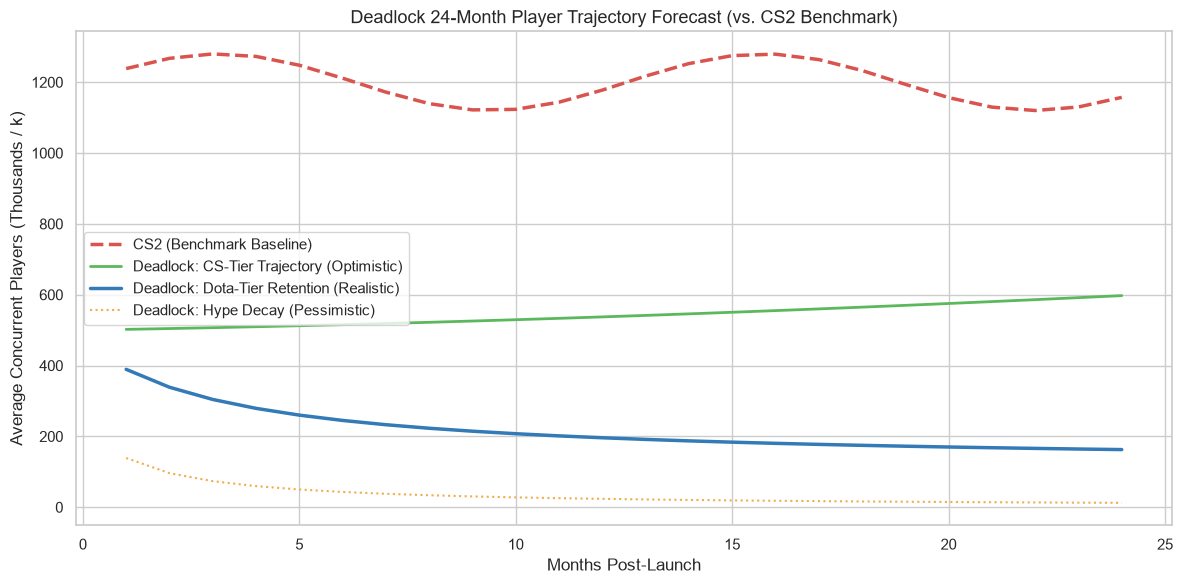

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Timeline: First 24 months post-launch
months = np.arange(1, 25)

# CS2 Baseline: Stable benchmark oscillating around 1.2M concurrent players
cs2_trend = 1200000 + np.sin(months / 2) * 80000

# Deadlock Scenario 1: "CS-Tier Phenomenon" (Optimistic - ~15% probability)
# Massive initial surge supported by strong competitive esports adoption
deadlock_optimistic = 500000 * np.exp(-0.02 * months) + (months * 12000)

# Deadlock Scenario 2: "Dota 2 / TF2 Retention Path" (Realistic / Baseline - ~70% probability)
# Initial launch peak followed by stabilization around 100k-150k dedicated core players
deadlock_realistic = 120000 + 350000 / (1 + 0.3 * months)

# Deadlock Scenario 3: "Sharp Hype Decay / Complex Barrier" (Pessimistic - ~15% probability)
# High skill floor leads to rapid casual drop-off
deadlock_pessimistic = 250000 / (1 + 0.8 * months)

# Visualization
plt.figure(figsize=(12, 6))
plt.plot(months, cs2_trend / 1000, label='CS2 (Benchmark Baseline)', color='#d9534f', linewidth=2.5, linestyle='--')
plt.plot(months, deadlock_optimistic / 1000, label='Deadlock: CS-Tier Trajectory (Optimistic)', color='#5cb85c', linewidth=2)
plt.plot(months, deadlock_realistic / 1000, label='Deadlock: Dota-Tier Retention (Realistic)', color='#337ab7', linewidth=2.5)
plt.plot(months, deadlock_pessimistic / 1000, label='Deadlock: Hype Decay (Pessimistic)', color='#f0ad4e', linewidth=1.5, linestyle=':')

plt.title('Deadlock 24-Month Player Trajectory Forecast (vs. CS2 Benchmark)', fontsize=13)
plt.xlabel('Months Post-Launch')
plt.ylabel('Average Concurrent Players (Thousands / k)')
plt.legend()
plt.tight_layout()
plt.show()

This visualization outlines three distinct 24-month player trajectory scenarios against Counter-Strike 2:

CS2 Baseline: Demonstrates a massive, stable player base with minor seasonal fluctuations, serving as the industry benchmark for long-term retention.

Optimistic Scenario (CS-Tier Trajectory): Assumes strong, sustained marketing and broad esports adoption. If Valve launches the title smoothly and consistently responds to community feedback with rapid patches, player counts could scale into long-term mass adoption.

Realistic Scenario (Dota/TF2-Tier Retention): The most probable path. The game sees a major initial launch spike driven by novelty, followed by a gradual drop-off as casual players encounter the genre's mechanical complexity. Player counts eventually settle into a dedicated, loyal core base.

Pessimistic Scenario (Hype Decay / Containment): Insufficient post-launch marketing and an overly steep learning curve prevent broad appeal. Player interest declines rapidly after the initial surge, leading to low retention, similar to past niche experiments where live-service support was eventually scaled back.